# Quick start: a whole Lorenz trajectory at once

An ODE is usually solved one time step after another; here we solve one trajectory for all its time steps at once.
This is the run of the animation in the [README](README.md): the bistable Lorenz system, 10,000 Euler steps, from a
guess that sits on the saddle. Run it from the repository root after the install in the README (add
`pip install jupyterlab` to open it in a browser); a CPU is enough.

In [1]:
import json

import jax

jax.config.update("jax_enable_x64", True)          # float64
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb

from parode import LaserConfig, explicit_par_integrate, seq_integrate

with open("figs/colors.json") as f:
    COLORS = json.load(f)["methods"]                # the method colors of the paper's figures
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "savefig.facecolor": "white",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## The problem

The Lorenz system with rho = 10 has a saddle at the origin and two stable equilibria, C+ and C-. The guess is the
zero trajectory, which sits on the saddle. `seq_integrate` takes the Euler steps one after another and gives the
reference solution: the one trajectory whose residual, the largest amount by which it breaks an Euler step, is zero.

In [2]:
sigma, rho, beta = 10.0, 10.0, 8.0 / 3.0


def lorenz(t, x):
    return jnp.array([sigma * (x[1] - x[0]), x[0] * (rho - x[2]) - x[1], x[0] * x[1] - beta * x[2]])


x0, dt, N = jnp.array([1.0, 1.0, 1.0]), 0.001, 10_000     # explicit Euler up to t = N dt = 10
tol, max_iter = 1e-9, 200
guess = jnp.zeros((N, 3))                                  # the states x_1 .. x_N (x_0 is fixed): the saddle
c = np.sqrt(beta * (rho - 1.0))
C_plus, C_minus = np.array([c, c, rho - 1.0]), np.array([-c, -c, rho - 1.0])   # the stable equilibria

sequential = np.asarray(seq_integrate(lorenz, x0, dt, N, "euler"))          # (N + 1, 3), with x0
t = dt * np.arange(N + 1)


def residual(sol):
    # max |x_{n+1} - x_n - dt f(x_n)|: zero exactly at the solution of the Euler steps
    f = jax.vmap(lambda x: lorenz(0.0, x))(sol[:-1])
    return float(jnp.max(jnp.abs(sol[1:] - sol[:-1] - dt * f)))


print(f"Lorenz with sigma = {sigma:g}, rho = {rho:g}, beta = 8/3, x0 = (1, 1, 1)")
print(f"explicit Euler, dt = {dt:g}, N = {N:,} steps; residual of the guess {residual(jnp.vstack((x0, guess))):.2f}")
point = lambda v: "(" + ", ".join(f"{x:.3f}" for x in v) + ")"
print(f"the sequential solution ends at {point(sequential[-1])}, next to C+ = {point(C_plus)}")

Lorenz with sigma = 10, rho = 10, beta = 8/3, x0 = (1, 1, 1)


explicit Euler, dt = 0.001, N = 10,000 steps; residual of the guess 1.01
the sequential solution ends at (4.914, 4.906, 9.027), next to C+ = (4.899, 4.899, 9.000)


## DEER and LASER

DEER is Newton's method over the whole trajectory: each iteration solves a linear problem for all time steps at
once, with a parallel scan. LASER is the damped Newton method of the paper, turned on by `laser=LaserConfig()`. From
the saddle, DEER blows up and LASER converges to the sequential solution.

In [3]:
# k, the cap on the iterations, is traced: each solver compiles once and serves every k
deer_solve = jax.jit(lambda k: explicit_par_integrate(lorenz, x0, guess, dt, k, "euler", tol=tol))
laser_solve = jax.jit(lambda k: explicit_par_integrate(lorenz, x0, guess, dt, k, "euler", tol=tol,
                                                       laser=LaserConfig()))

for name, solve in (("DEER", deer_solve), ("LASER", laser_solve)):     # the loop ends with LASER
    sol, _, iterations = solve(max_iter)            # sol (N + 1, 3) with x0
    error = float(jnp.max(jnp.abs(sol - sequential)))
    print(f"{name:5s} {int(iterations):3d} iterations   residual {residual(sol):.1e}   "
          f"max |{name} - sequential| {error:.1e}")
print(f"DEER's residual after one iteration: {residual(deer_solve(1)[0]):.1e}")

K = int(iterations)
assert K == 19 and error < 1e-8, "LASER did not reproduce the run of the animation"

DEER    2 iterations   residual nan   max |DEER - sequential| nan


LASER  19 iterations   residual 1.2e-13   max |LASER - sequential| 1.2e-10
DEER's residual after one iteration: 1.9e+44


## The iterates

The iterate after k iterations is the solve with `max_iter = k`. LASER's iterates leave the saddle, walk toward C+
and settle on the sequential solution (dashed).

In [4]:
iterates = np.stack([laser_solve(k)[0] for k in range(K + 1)])     # (K + 1, N + 1, 3); k = 0 is the guess
errors = np.abs(iterates - sequential).max(axis=(1, 2))
print("max |iterate k - sequential|, k = 0 ..", K)
print(" ".join(f"{e:.0e}" for e in errors))

max |iterate k - sequential|, k = 0 .. 19
1e+01 1e+01 1e+01 1e+01 1e+01 1e+01 1e+01 1e+01 1e+01 1e+01 8e+00 6e+00 6e+00 5e+00 3e+00 1e+00 1e-01 2e-03 1e-06 1e-10


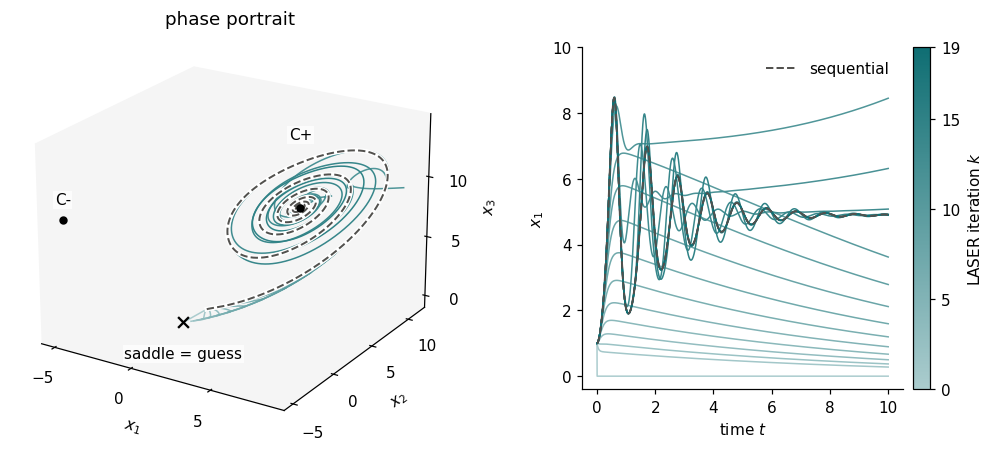

In [5]:
laser_rgb = np.array(to_rgb(COLORS["LASER"]))
cmap = LinearSegmentedColormap.from_list("iterations", [0.35 * laser_rgb + 0.65, laser_rgb])   # early -> late

fig = plt.figure(figsize=(10, 4.2))
ax3 = fig.add_axes([0.0, 0.0, 0.48, 0.95], projection="3d", computed_zorder=False)   # draw in the order below
ax = fig.add_axes([0.56, 0.14, 0.32, 0.74])
for k in range(K + 1):
    ax3.plot(*iterates[k].T, color=cmap(k / K), lw=1)
    ax.plot(t, iterates[k, :, 0], color=cmap(k / K), lw=1)
ax3.plot(*sequential.T, color="white", lw=3)                      # so that the dashes stand out from the iterates
ax3.plot(*sequential.T, color=COLORS["seq"], lw=1.3, ls="--")
ax.plot(t, sequential[:, 0], color=COLORS["seq"], lw=1.3, ls="--", label="sequential")

label = dict(ha="center", bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
ax3.scatter(0, 0, 0, marker="x", s=50, color="k", depthshade=False, zorder=3)
ax3.text(0, 0, -2.0, "saddle = guess", va="top", **label)
ax3.scatter(*np.array([C_plus, C_minus]).T, s=20, color="k", depthshade=False, zorder=3)
ax3.text(*(C_plus + [0, 0, 5.5]), "C+", **label)
ax3.text(*(C_minus + [0, 0, 1.2]), "C-", **label)
for axis in (ax3.xaxis, ax3.yaxis, ax3.zaxis):
    axis.set_pane_color((0.96, 0.96, 0.96, 1))
ax3.grid(False)
ax3.view_init(elev=22, azim=-58)
ax3.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$x_3$", xticks=[-5, 0, 5], yticks=[-5, 0, 5, 10], zticks=[0, 5, 10])
fig.text(0.24, 0.93, "phase portrait", ha="center", fontsize=12)

ax.set(xlabel="time $t$", ylabel="$x_1$", ylim=(-0.4, 10))
ax.legend(frameon=False, loc="upper right")
fig.colorbar(ScalarMappable(Normalize(0, K), cmap), ax=ax, label="LASER iteration $k$", fraction=0.06, pad=0.03,
             ticks=[0, 5, 10, 15, K])
plt.show()

## What LASER does

`LaserConfig(return_history=True)` also returns, per iteration, the residual, the exponent $\lambda_h$ of the new
iterate and the damping $\gamma$ of the Newton step. The exponent is a finite-time Lyapunov exponent, positive when
small errors grow along the iterate; the damping multiplies the Jacobians of the Euler steps by $e^{-\gamma\,dt}$. An
unstable iterate (positive exponent) gets strong damping, and the damping goes away as the iterate becomes stable.

In [6]:
history_solve = jax.jit(lambda: explicit_par_integrate(lorenz, x0, guess, dt, max_iter, "euler", tol=tol,
                                                       laser=LaserConfig(return_history=True)))
_, _, _, history = history_solve()
h = {name: np.asarray(values[:K]) for name, values in history.items()}    # row k - 1: iteration k

print(" k   residual   exponent   damping")
for k in range(1, K + 1):
    print(f"{k:2d}   {h['residual'][k - 1]:8.1e}   {h['lambda_h'][k - 1]:8.3f}   {h['gamma'][k - 1]:7.3f}")

 k   residual   exponent   damping
 1    6.5e-03      5.404     5.551
 2    8.2e-03      5.357    22.015
 3    1.1e-02      5.276    22.015
 4    1.4e-02      5.131    22.015
 5    1.8e-02      4.862    22.015
 6    2.2e-02      4.319    22.015
 7    2.6e-02      3.196    22.015
 8    2.8e-02      2.144    22.015
 9    3.6e-02      1.455    22.015
10    4.4e-02      1.179    22.015
11    7.0e-02      0.156     5.504
12    1.2e-02     -0.447     1.376
13    1.1e-02     -0.451     0.344
14    1.1e-02     -0.355     0.086
15    4.6e-03     -0.370     0.021
16    7.3e-04     -0.377     0.005
17    1.0e-05     -0.378     0.001
18    3.1e-09     -0.378     0.000
19    1.2e-13     -0.378     0.000


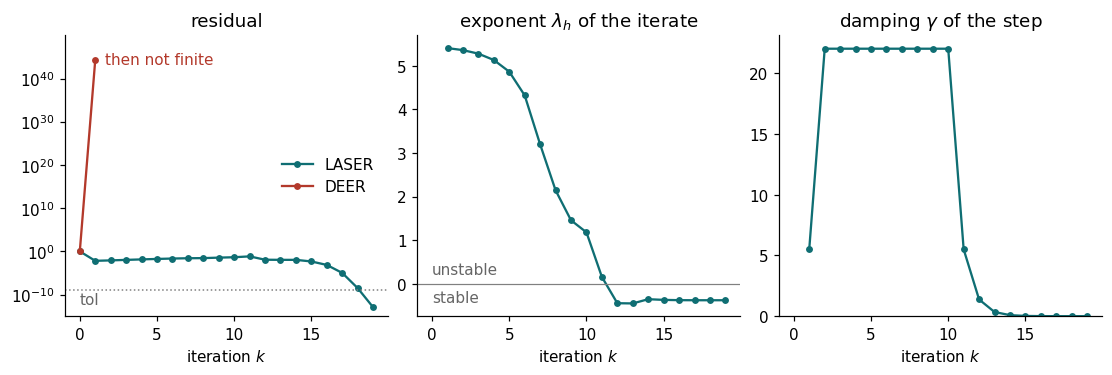

In [7]:
ks = np.arange(K + 1)
res_laser = np.concatenate([[residual(iterates[0])], h["residual"]])
res_deer = [res_laser[0], residual(deer_solve(1)[0])]       # its next iterate is not finite

fig, (a, b, g) = plt.subplots(1, 3, figsize=(10, 3.3), sharex=True, layout="constrained")
a.semilogy(ks, res_laser, "o-", ms=3.5, color=COLORS["LASER"], label="LASER")
a.semilogy([0, 1], res_deer, "o-", ms=3.5, color=COLORS["DEER"], label="DEER")
a.text(1.6, res_deer[1], "then not finite", va="center", color=COLORS["DEER"])
a.axhline(tol, ls=":", lw=1, color="0.5")
a.text(0, tol / 3, "tol", va="top", color="0.4")
a.set(title="residual", xlabel="iteration $k$", ylim=(1e-15, 1e50), yticks=[1e-10, 1e0, 1e10, 1e20, 1e30, 1e40])
a.legend(frameon=False, loc="center right")

b.plot(ks[1:], h["lambda_h"], "o-", ms=3.5, color=COLORS["LASER"])
b.axhline(0, lw=0.8, color="0.5")
b.text(0, 0.15, "unstable", va="bottom", color="0.4")
b.text(0, -0.15, "stable", va="top", color="0.4")
b.set(title=r"exponent $\lambda_h$ of the iterate", xlabel="iteration $k$")

g.plot(ks[1:], h["gamma"], "o-", ms=3.5, color=COLORS["LASER"])
g.set(title=r"damping $\gamma$ of the step", xlabel="iteration $k$", ylim=(0, None))
plt.show()

DEER's residual jumps to the order of $10^{44}$ after one iteration, and its next iterate is not finite. LASER's
residual stays below that of the guess while the damping is strong, then falls to the tolerance once the exponent
turns negative.

## Where to go next

- [`experiments/lorenz/`](experiments/lorenz/): the full experiment, with more solvers, longer horizons and the GPU
  timings.
- [`examples/own_ode.py`](examples/own_ode.py): a template for your own ODE, with inputs, batches and gradients.
- [`docs/solvers.md`](docs/solvers.md): every argument of the solvers.